# Imports

In [21]:
# %pip install tensorflow
# %pip install --upgrade tensorflow keras
# %pip install keras_tuner
# %pip install huggingface_hub
# %pip install datasets
# %pip install ipywidgets

In [23]:
import os
import re
import glob
import json
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from PIL import Image
import keras
from keras import layers
import keras_tuner as kt
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

RANDOM_STATE = 1234

In [2]:
def load_npz_dataframe(
    data_dir="data/", 
    metadata_path="vial_metadata.json", 
    train_size=0.7, 
    val_size=0.20, 
    test_size=0.10
):    
    """
    Scans the data directory, reads the JSON registry, dynamically maps 
    encountered species to integer labels, and handles small-batch splitting.
    """
    assert abs((train_size + val_size + test_size) - 1.0) < 1e-5, "Split proportions must sum to 1.0"
    with open(metadata_path, 'r', encoding='utf-8') as f:
        vial_registry = json.load(f)
        
    files = glob.glob(os.path.join(data_dir, "*.npz"))
    data = []
    for f in files:
        file_name = os.path.basename(f)
        parts = file_name.split('_')
        vial_number, sample_letter, capture_number = parts[0], parts[1], parts[2].replace(".npz", "")
        if len(parts) < 3:
            print(f"Warning: Unexpected filename format for {file_name}. Skipping.")
            continue
        if vial_number in vial_registry:
            species_id = vial_registry[vial_number].get("Species ID")
            data.append({
                "filepath": f, 
                "vial": vial_number,
                "sample": sample_letter,
                "capture": capture_number,
                "species": species_id
            })
                
    df = pd.DataFrame(data)        
    unique_species = df['species'].unique()
    species_to_label = {species: i for i, species in enumerate(unique_species)}
    df['label'] = df['species'].map(species_to_label)
    
    min_class_count = df['label'].value_counts().min()
    use_stratify = df['label'] if min_class_count >= 4 else None
    if use_stratify is None:
        print("Notice: Class counts too low for stratification. Using random split.")
    
    # Split 1: Separate Train from (Val + Test)
    temp_size = val_size + test_size
    train_df, temp_df = train_test_split(
        df, test_size=temp_size, stratify=use_stratify, random_state=RANDOM_STATE
    )

    # Split 2: Separate Val from Test
    temp_min = temp_df['label'].value_counts().min()
    use_stratify_temp = temp_df['label'] if (use_stratify is not None and temp_min >= 2) else None
    
    # Calculate what fraction of the temp_df needs to go to the test set
    test_fraction_of_temp = test_size / temp_size
    val_df, test_df = train_test_split(
        temp_df, test_size=test_fraction_of_temp, stratify=use_stratify_temp, random_state=RANDOM_STATE
    )
    
    print(f"Loaded {len(train_df)} training, {len(val_df)} validation, and {len(test_df)} testing samples.")
    return train_df, val_df, test_df, len(unique_species)
train_df, val_df, test_df, NUM_CLASSES = load_npz_dataframe()

Loaded 6 training, 2 validation, and 2 testing samples.


In [ ]:
# method 0: just take all the rgb channels 

# method 1: take the average of the rgb channels
def collapse_average(img_array):
    """Calculates the raw unweighted mean across the 3 color channels. Simplest form of monochrome collapse."""
    return np.mean(img_array, axis=-1)

# method 2: take a weighted average based on channel intensity so that weak channels are given less weight, as they are more likely to be noise
def collapse_sensitivity_aware(img_array):
    """Calculates a weighted monochrome collapse based on channel intensity. Very similar to the average just with a weighting based on brightness of each channel."""
    channel_intensities = np.mean(img_array, axis=(0, 1))
    total_intensity = np.sum(channel_intensities)
    weights = channel_intensities / total_intensity
    print(f"Channel intensities: {channel_intensities}; Weights: {weights}")
    return np.dot(img_array, weights)

# method 3: take a weighted average based on the physical sensor profile for the specific wavelength of the LED illuminating the frame
with open('imx571_spectral_profile.json', 'r') as f:
    sensor_profile = json.load(f)

def get_profile_weights(wavelength_nm):
    """Looks up the normalized RGB response weights for a specific wavelength."""
    min_w = sensor_profile['min_wavelength']
    max_w = sensor_profile['max_wavelength']
    w = max(min_w, min(int(wavelength_nm), max_w))
    idx = w - min_w
    r = sensor_profile['normalized_response']['R'][idx]
    g = sensor_profile['normalized_response']['G'][idx]
    b = sensor_profile['normalized_response']['B'][idx]
    total = r + g + b
    if total == 0:
        return np.array([1/3, 1/3, 1/3])
    return np.array([r/total, g/total, b/total])

def collapse_profile_aware(img_array, band_name):
    """
    Collapses the RGB channels using the physical sensor profile weights 
    for the specific LED wavelength illuminating the frame.
    """
    match = re.search(r'_(\d+)nm', band_name)# extract the wavelength from strings like "Band 8_640nm_R"
    if not match:
        raise ValueError(f"Could not extract wavelength from band name: {band_name}")
    wavelength = int(match.group(1))
    weights = get_profile_weights(wavelength)
    return np.dot(img_array, weights)

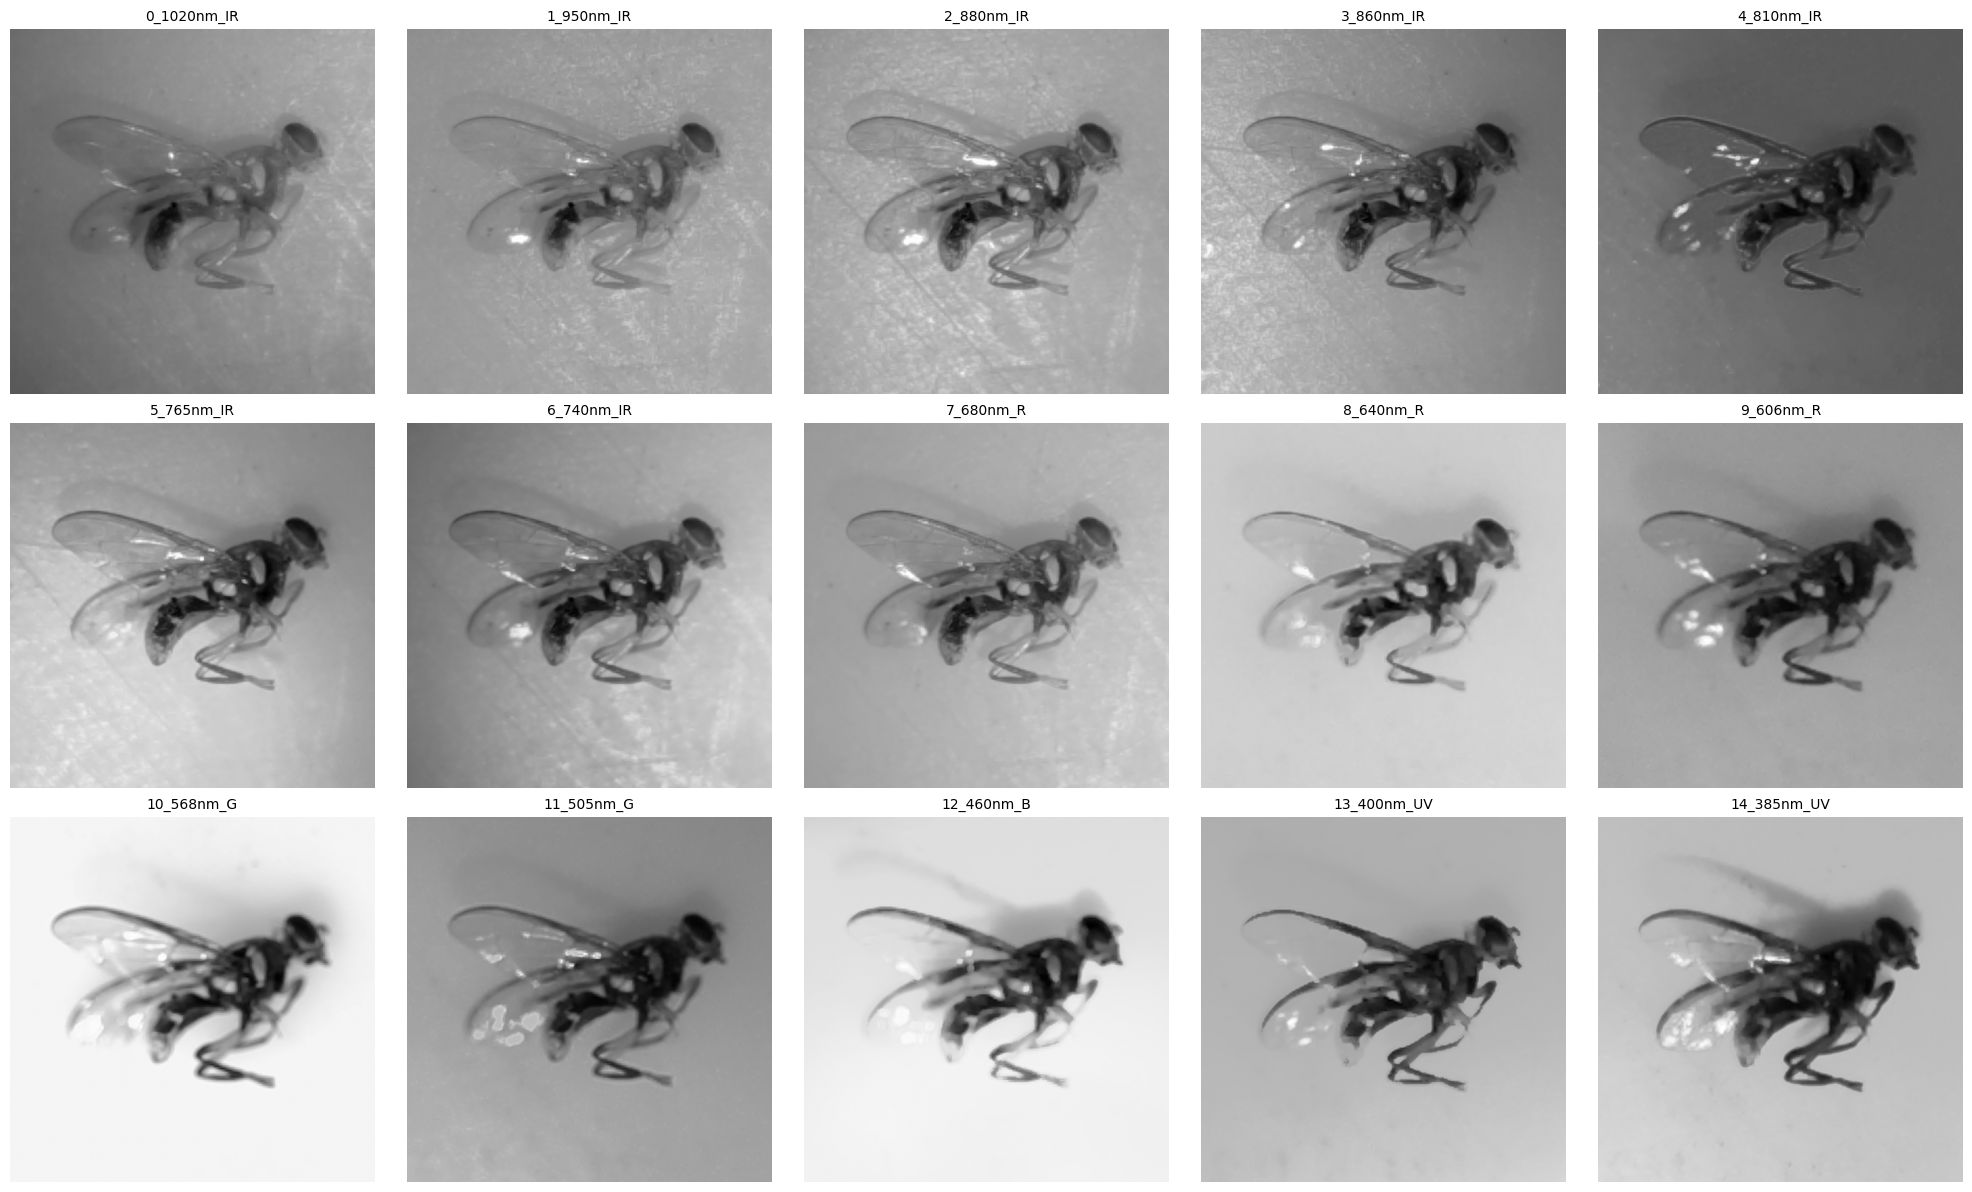

In [ ]:
def static_cube_grid(filepath, collapse_method=None):
    with np.load(filepath, allow_pickle=True) as data:
        img_cube = data['data']
        bands = data['bands']
        
    fig, axes = plt.subplots(3, 5, figsize=(20, 12))
    axes = axes.flatten()
    
    for i in range(15):
        band_slice = img_cube[:, :, :, i]
        band_name = bands[i]
        
        if collapse_method is None:
            # Leave as raw RGB (BGR to RGB fix applied)
            display_img = band_slice[..., ::-1]
            cmap = None
        else:
            # Pass BOTH the image array and the band name to the custom function
            display_img = collapse_method(band_slice, band_name)
            cmap = 'gray'
            
        axes[i].imshow(display_img, cmap=cmap)
        axes[i].set_title(band_name, fontsize=10)
        axes[i].axis('off')
        
    plt.tight_layout()
    plt.show()

static_cube_grid(train_df.iloc[0]['filepath'], collapse_method=None)

In [18]:
# 2. Build the multispectral tf.data pipeline
def create_multispectral_tf_dataset(df, num_spectral_bands=15, batch_size=32, img_size=(224, 224), is_training=False):
    paths = df['filepath'].values
    labels = df['label'].values
    total_channels = 3 * num_spectral_bands
    
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    
    def load_npz_image(path, label):
        def _load_numpy(file_path):
            file_path = file_path.decode('utf-8')
            with np.load(file_path, allow_pickle=True) as data:
                img = data['data'] 
            h, w, c, b = img.shape
            img_reshaped = img.reshape(h, w, c * b)
            return img_reshaped.astype(np.float32) / 255.0

        img = tf.numpy_function(_load_numpy, [path], tf.float32)
        img.set_shape((700, 700, total_channels))
        img = tf.image.resize(img, img_size)
        return img, label
        
    ds = ds.map(load_npz_image, num_parallel_calls=tf.data.AUTOTUNE)
    if is_training:
        ds = ds.shuffle(buffer_size=len(df))
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

train_dataset = create_multispectral_tf_dataset(train_df, is_training=True)
val_dataset = create_multispectral_tf_dataset(val_df)
test_dataset = create_multispectral_tf_dataset(test_df)


In [19]:
# 3. Keras Tuner Model Builder
def model_builder(hp):
    model = keras.Sequential()
    model.add(layers.Input(shape=(224, 224, 45))) 

    # Conv Layer 1
    model.add(layers.Conv2D(
        filters=hp.Int('filters1', 32, 128, step=16),
        kernel_size=hp.Choice('kernel1', [3, 5]),
        activation='relu',
        padding='same'
    ))
    if hp.Choice("layer_1_pool_type", ["max", "avg"]) == "max":
        model.add(layers.MaxPooling2D())
    else:
        model.add(layers.AveragePooling2D(pool_size=(2, 2)))
    
    if hp.Boolean('use_dropout1'):
        model.add(layers.Dropout(hp.Float('dropout1', 0.1, 0.5)))

    # Conv Layer 2
    model.add(layers.Conv2D(
        filters=hp.Int('filters2', 32, 128, step=16),
        kernel_size=hp.Choice('kernel2', [3, 5]),
        activation='relu',
        padding='same'
    ))
    if hp.Choice("layer_2_pool_type", ["max", "avg"]) == "max":
        model.add(layers.MaxPooling2D())
    else:
        model.add(layers.AveragePooling2D(pool_size=(2, 2)))

    model.add(layers.Flatten())
    model.add(layers.Dense(
        units=hp.Int('dense_units', 64, 256, step=32),
        activation='relu'
    ))

    if hp.Boolean('use_dropout2'):
        model.add(layers.Dropout(hp.Float('dropout2', 0.1, 0.5)))

    # Dynamically scale output nodes based on discovered species
    model.add(layers.Dense(NUM_CLASSES, activation='softmax'))

    learning_rate = hp.Float('lr', 1e-5, 1e-2, sampling='log')
    optimizer_choice = hp.Choice('optimizer', ['adam', 'rmsprop'])
    opt = keras.optimizers.Adam(learning_rate) if optimizer_choice == 'adam' else keras.optimizers.RMSprop(learning_rate)

    model.compile(
        optimizer=opt,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model